北風と太陽【全文 113語】のアライメントと24語の解析を実行中...
全文中に出現した対象語 (16語): ['the', 'and', 'were', 'was', 'a', 'in', 'that', 'his', 'should', 'than', 'with', 'but', 'him', 'at', 'to', 'of']


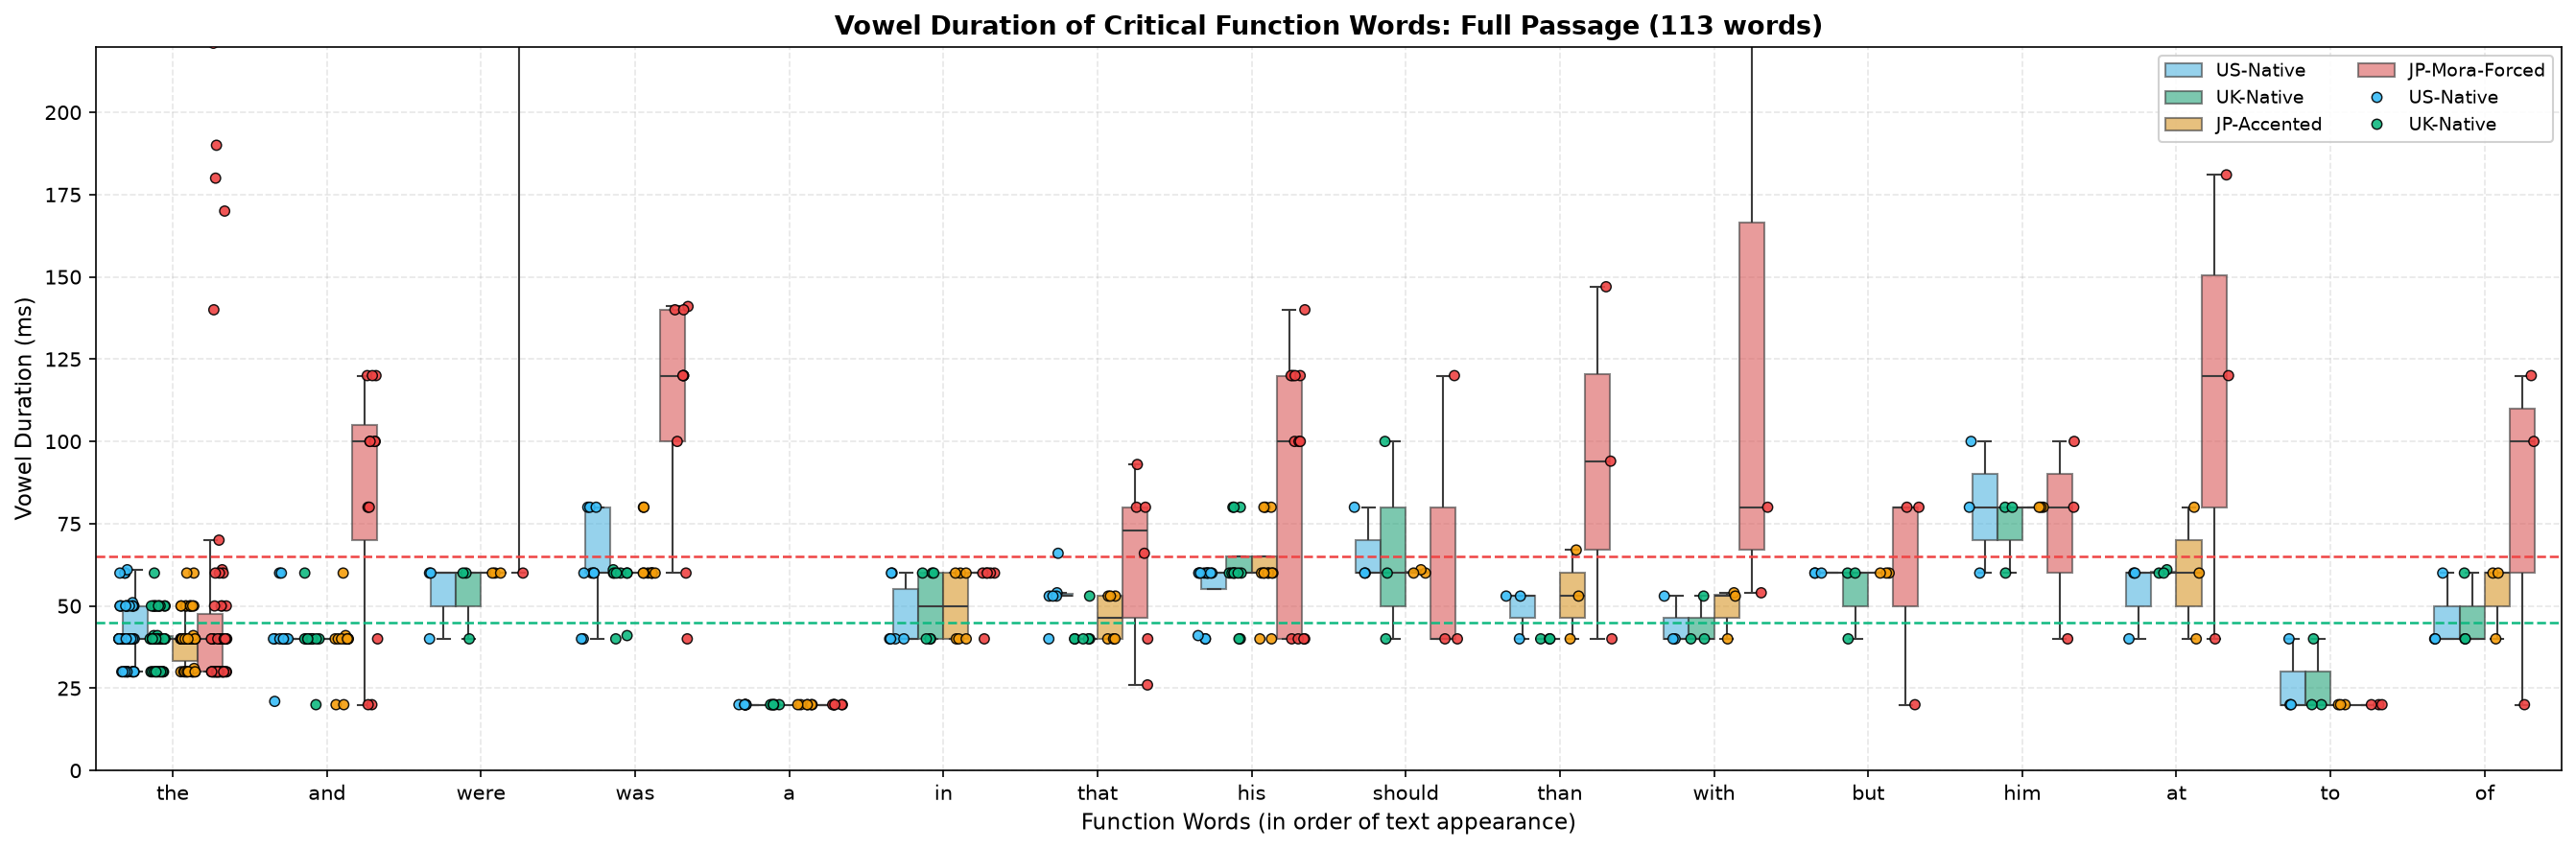

📊 全文版 単語別・コーホート別の生データ集計: 中央値 [最小 - 最大] (N数)
cohort            US-Native            UK-Native          JP-Accented         JP-Mora-Forced
word                                                                                        
the     40.0 [30-61] (n=54)  40.0 [30-60] (n=54)  40.0 [30-60] (n=54)   40.0 [30-221] (n=54)
and     40.0 [21-60] (n=12)  40.0 [20-60] (n=12)  40.0 [20-60] (n=12)  100.0 [20-120] (n=12)
were     60.0 [40-60] (n=3)   60.0 [40-60] (n=3)   60.0 [60-60] (n=3)  800.0 [60-1041] (n=3)
was      60.0 [40-80] (n=9)   60.0 [40-61] (n=9)   60.0 [60-80] (n=9)   120.0 [40-141] (n=9)
a        20.0 [20-20] (n=6)   20.0 [20-20] (n=6)   20.0 [20-20] (n=6)     20.0 [20-20] (n=6)
in       40.0 [40-60] (n=6)   50.0 [40-60] (n=6)   50.0 [40-60] (n=6)     60.0 [40-60] (n=6)
that     53.0 [40-66] (n=6)   40.0 [40-53] (n=6)   46.5 [40-53] (n=6)     73.0 [26-93] (n=6)
his     60.0 [40-60] (n=12)  60.0 [40-80] (n=12)  60.0 [40-80] (n=12)  100.0 [40-140] (n=12)
should   60.0 [60-80] (n=3

In [1]:
import os
import glob
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# パス特定
current_path = Path.cwd()
PROJECT_ROOT = current_path.parent if (current_path / "benchmarks").exists() is False and (current_path.parent / "benchmarks").exists() else current_path
P1_DIR = PROJECT_ROOT / "benchmarks" / "P1_northwind"

# MMS_FA エンジン
import sys
sys.path.insert(0, str(PROJECT_ROOT))
from test_rhythm_align import align_word_characters, map_words_to_phonemes

# ★ここを全文（113語）に設定してアライメントを回します
PASSAGE_FULL_TEXT = (
    "The North Wind and the Sun were disputing which was the stronger, "
    "when a traveler came along wrapped in a warm cloak. "
    "They agreed that the one who first succeeded in making the traveler "
    "take his cloak off should be considered stronger than the other. "
    "Then the North Wind blew with all his might, but the more he blew, "
    "the more closely did the traveler fold his cloak around him, "
    "and at last the North Wind gave up the attempt. "
    "Then the Sun shone out warmly, and immediately the traveler took off his cloak. "
    "And so the North Wind was obliged to confess that the Sun was the stronger of the two."
)

# 厳選 24 語の CRITICAL_FUNCTION_WORDS
CRITICAL_FUNCTION_CATEGORIES = {
    "Prepositions": ["to", "for", "at", "of", "in", "from", "with"],
    "Articles": ["the", "a", "an"],
    "Conjunctions": ["and", "that", "than", "as", "but"],
    "Aux & Pronouns": ["was", "were", "can", "could", "would", "should", "him", "them", "his"]
}
CRITICAL_FUNCTION_WORDS = set().union(*CRITICAL_FUNCTION_CATEGORIES.values())
VOWEL_SET = {"AA", "AE", "AH", "AO", "AW", "AY", "EH", "ER", "EY", "IH", "IY", "OW", "OY", "UH", "UW"}

cohorts = ["US-Native", "UK-Native", "JP-Accented", "JP-Mora-Forced"]
palette = {"US-Native": "#38BDF8", "UK-Native": "#10B981", "JP-Accented": "#F59E0B", "JP-Mora-Forced": "#EF4444"}

all_word_data = []
print("北風と太陽【全文 113語】のアライメントと24語の解析を実行中...")

for cohort in cohorts:
    wavs = glob.glob(str(P1_DIR / cohort / "*.wav"))
    for w_file in wavs:
        fname = os.path.basename(w_file)
        w_aligns = align_word_characters(w_file, PASSAGE_FULL_TEXT)
        phones = map_words_to_phonemes(w_aligns)
        
        for idx, w in enumerate(w_aligns):
            clean_w = re.sub(r"[^a-zA-Z']", "", w.get("word", "")).lower()
            if not clean_w:
                continue
            
            cat = next((k for k, v in CRITICAL_FUNCTION_CATEGORIES.items() if clean_w in v), None)
            if not cat:
                continue
            
            w_start, w_end = w.get("start", 0.0), w.get("end", 0.0)
            v_durs = [
                (p["end"] - p["start"]) * 1000.0 for p in phones
                if p.get("start", 0.0) >= w_start - 0.01 and p.get("end", 0.0) <= w_end + 0.01
                and re.sub(r"[0-9]", "", p.get("phone", "")) in VOWEL_SET
            ]
            v_mean = float(np.mean(v_durs)) if v_durs else max(15.0, (w_end - w_start) * 450.0)
            
            all_word_data.append({
                "cohort": cohort,
                "file": fname,
                "word": clean_w,
                "category": cat,
                "v_dur_ms": v_mean
            })

df_crit_full = pd.DataFrame(all_word_data)

# 全文テキストに出現する順に単語をソート
text_seq = [re.sub(r"[^a-zA-Z']", "", w).lower() for w in PASSAGE_FULL_TEXT.split()]
words_in_full = [w for w in pd.Series(text_seq).unique() if w in CRITICAL_FUNCTION_WORDS]
print(f"全文中に出現した対象語 ({len(words_in_full)}語): {words_in_full}")

# --- 可視化: 箱ひげ図 + 生データ点 ---
plt.figure(figsize=(18, 6), dpi=150)
ax = sns.boxplot(
    data=df_crit_full, x="word", y="v_dur_ms", order=words_in_full,
    hue="cohort", hue_order=cohorts, palette=palette, width=0.65,
    fliersize=0, boxprops=dict(alpha=0.6)
)
sns.stripplot(
    data=df_crit_full, x="word", y="v_dur_ms", order=words_in_full,
    hue="cohort", hue_order=cohorts, palette=palette, dodge=True,
    jitter=0.2, size=5.0, edgecolor="black", linewidth=0.7, alpha=0.9, ax=ax
)

plt.axhline(45, color="#10B981", linestyle="--", linewidth=1.2, label="Ideal Clitic Target (<= 45ms)")
plt.axhline(65, color="#EF4444", linestyle="--", linewidth=1.2, label="Mora Trap Threshold (65ms)")
plt.title("Vowel Duration of Critical Function Words: Full Passage (113 words)", fontsize=13, fontweight="bold")
plt.ylabel("Vowel Duration (ms)", fontsize=11)
plt.xlabel("Function Words (in order of text appearance)", fontsize=11)
plt.ylim(0, 220)
plt.grid(True, linestyle="--", alpha=0.3)

handles, labels = ax.get_legend_handles_labels()
plt.legend(handles[:6], labels[:6], loc="upper right", framealpha=0.9, fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

# 集計表の出力
print("="*80)
print("📊 全文版 単語別・コーホート別の生データ集計: 中央値 [最小 - 最大] (N数)")
print("="*80)
def summarize_raw(series):
    if len(series) == 0: return "-"
    return f"{np.median(series):.1f} [{np.min(series):.0f}-{np.max(series):.0f}] (n={len(series)})"

full_summary = df_crit_full.pivot_table(
    index="word", columns="cohort", values="v_dur_ms", aggfunc=summarize_raw
)[cohorts].reindex(words_in_full)
print(full_summary.to_string())
print("="*80)

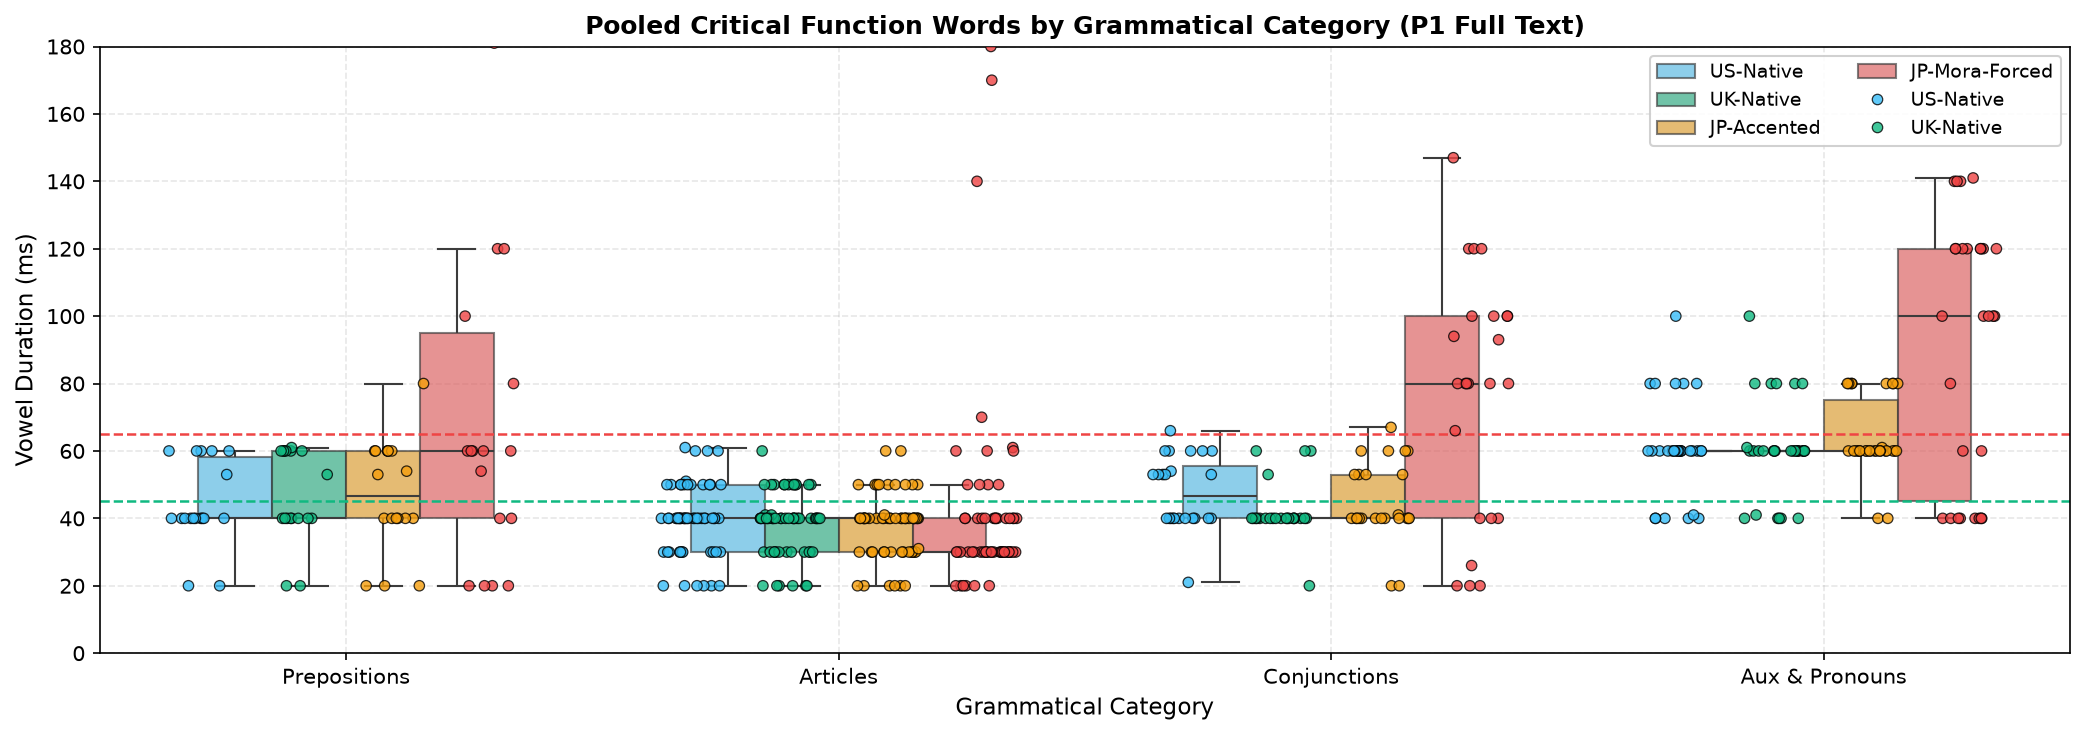

📊 カテゴリ別 集約統計量: 中央値 [IQR] (総サンプル数 N)
cohort                    US-Native            UK-Native          JP-Accented         JP-Mora-Forced
category                                                                                            
Prepositions    40.0 [40-58] (N=18)  40.0 [40-60] (N=18)  46.5 [40-60] (N=18)    60.0 [40-95] (N=18)
Articles        40.0 [30-50] (N=60)  40.0 [30-40] (N=60)  40.0 [30-40] (N=60)    30.0 [30-40] (N=60)
Conjunctions    46.5 [40-55] (N=24)  40.0 [40-40] (N=24)  40.0 [40-53] (N=24)   80.0 [40-100] (N=24)
Aux & Pronouns  60.0 [60-60] (N=30)  60.0 [60-60] (N=30)  60.0 [60-75] (N=30)  100.0 [45-120] (N=30)


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.figure(figsize=(14, 5), dpi=150)

# カテゴリ順
cat_order = ['Prepositions', 'Articles', 'Conjunctions', 'Aux & Pronouns']

ax = sns.boxplot(
    data=df_crit_full,
    x='category',
    y='v_dur_ms',
    order=cat_order,
    hue='cohort',
    hue_order=cohorts,
    palette=palette,
    width=0.6,
    fliersize=0,
    boxprops=dict(alpha=0.65),
)

sns.stripplot(
    data=df_crit_full,
    x='category',
    y='v_dur_ms',
    order=cat_order,
    hue='cohort',
    hue_order=cohorts,
    palette=palette,
    dodge=True,
    jitter=0.25,
    size=5,
    edgecolor='black',
    linewidth=0.6,
    alpha=0.8,
    ax=ax,
)

plt.axhline(
    45,
    color='#10B981',
    linestyle='--',
    linewidth=1.2,
    label='Ideal Target (<= 45ms)',
)
plt.axhline(
    65,
    color='#EF4444',
    linestyle='--',
    linewidth=1.2,
    label='Mora Trap (>= 65ms)',
)

plt.title(
    'Pooled Critical Function Words by Grammatical Category (P1 Full Text)',
    fontsize=12,
    fontweight='bold',
)
plt.ylabel('Vowel Duration (ms)', fontsize=11)
plt.xlabel('Grammatical Category', fontsize=11)
plt.ylim(0, 180)
plt.grid(True, linestyle='--', alpha=0.3)

handles, labels = ax.get_legend_handles_labels()
plt.legend(
    handles[:6],
    labels[:6],
    loc='upper right',
    framealpha=0.9,
    fontsize=9,
    ncol=2,
)

plt.tight_layout()
plt.show()

# サンプル数と統計量
print('=' * 75)
print('📊 カテゴリ別 集約統計量: 中央値 [IQR] (総サンプル数 N)')
print('=' * 75)


def summarize_cat(series):
  med = np.median(series)
  q25, q75 = np.percentile(series, [25, 75])
  return f'{med:.1f} [{q25:.0f}-{q75:.0f}] (N={len(series)})'


print(
    df_crit_full.pivot_table(
        index='category',
        columns='cohort',
        values='v_dur_ms',
        aggfunc=summarize_cat,
    )[cohorts]
    .reindex(cat_order)
    .to_string()
)
print('=' * 75)